In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import re
from collections import Counter

In [17]:
train = pd.read_csv(
    "/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv"
)

test = pd.read_csv(
    "/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv"
)

In [18]:
train.head()

,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


In [19]:
print("Train Shape :", train.shape)
print("Test Shape :", test.shape)

train.info()

Train Shape : (2000, 8)
Test Shape : (500, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


In [20]:
train.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

In [21]:
test.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
dtype: int64

In [22]:
#Target Distribution
train["answer"].value_counts().sort_index()

answer
A    369
B    490
C    459
D    358
E    324
Name: count, dtype: int64

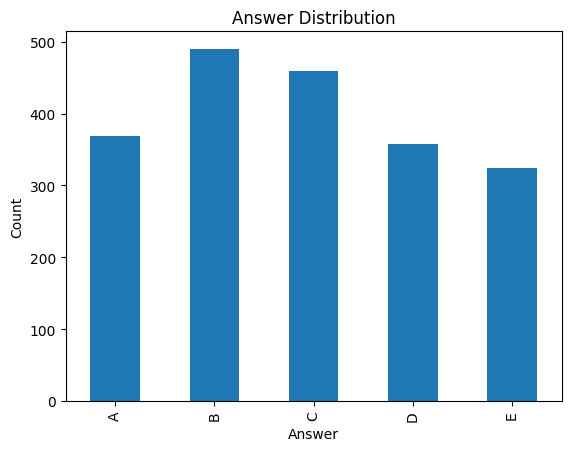

In [23]:
train["answer"].value_counts().sort_index().plot(
    kind="bar"
)

plt.title("Answer Distribution")
plt.xlabel("Answer")
plt.ylabel("Count")
plt.show()

In [24]:
#Prompt Length Analysis
train["prompt_length"] = train["prompt"].str.len()

train["prompt_length"].describe()

count    2000.000000
mean      117.669500
std        44.408674
min        19.000000
25%        87.750000
50%       111.000000
75%       141.000000
max       337.000000
Name: prompt_length, dtype: float64

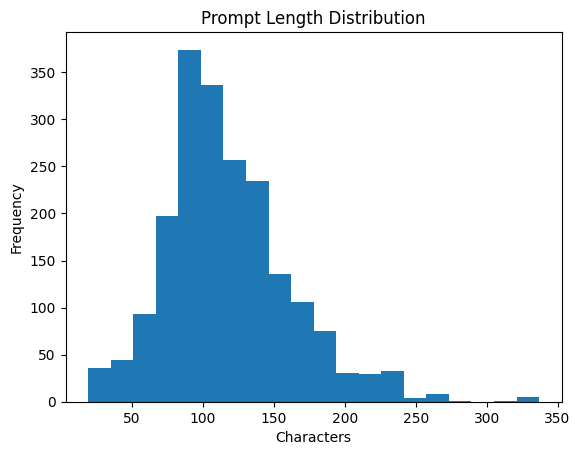

In [25]:
plt.hist(train["prompt_length"], bins=20)

plt.title("Prompt Length Distribution")
plt.xlabel("Characters")
plt.ylabel("Frequency")

plt.show()

In [26]:
#Option length analysis
for col in ["A","B","C","D","E"]:

    train[f"{col}_length"] = train[col].str.len()

train[
    ["A_length","B_length","C_length","D_length","E_length"]
].describe()

,A_length,B_length,C_length,D_length,E_length
count,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000
mean,164.091500,166.616500,167.227000,162.56350,164.230000
std,105.677145,113.829917,105.723674,104.11657,107.777712
min,1.000000,2.000000,2.000000,1.00000,2.000000
25%,86.000000,82.000000,88.000000,91.00000,84.000000
50%,143.000000,151.000000,158.000000,141.00000,144.000000
75%,234.000000,222.000000,224.000000,231.00000,224.000000
max,472.000000,662.000000,530.000000,450.00000,587.000000


In [27]:
duplicates = train["prompt"].duplicated().sum()

print("Duplicate Prompts :", duplicates)

Duplicate Prompts : 242


In [28]:
#Prompt Word count
train["prompt_word_count"] = train["prompt"].str.split().str.len()

train["prompt_word_count"].describe()

count    2000.00000
mean       18.14650
std         6.78189
min         3.00000
25%        14.00000
50%        17.00000
75%        22.00000
max        51.00000
Name: prompt_word_count, dtype: float64

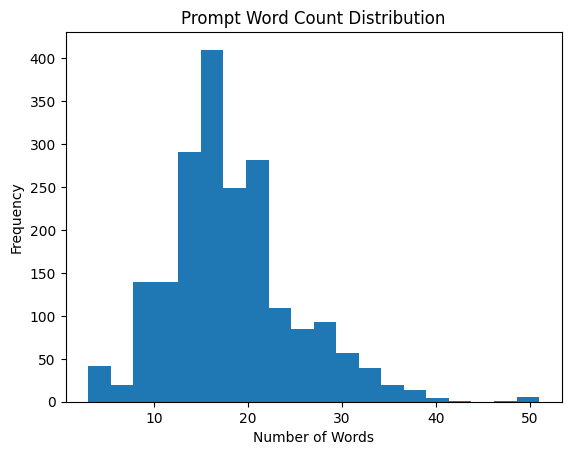

In [29]:
plt.hist(train["prompt_word_count"], bins=20)

plt.title("Prompt Word Count Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")

plt.show()

In [30]:
#Vocab Size
all_text = " ".join(
    train["prompt"].tolist() +
    train["A"].tolist() +
    train["B"].tolist() +
    train["C"].tolist() +
    train["D"].tolist() +
    train["E"].tolist()
)

vocab = set(all_text.split())

print("Vocabulary Size:", len(vocab))

Vocabulary Size: 3955


In [31]:
#Most frequent words
from collections import Counter

counter = Counter(all_text.split())

top_words = counter.most_common(20)

top_words

[('the', 22834),
 ('of', 14606),
 ('a', 10795),
 ('is', 10182),
 ('and', 6917),
 ('in', 6581),
 ('to', 6003),
 ('that', 4348),
 ('The', 4332),
 ('by', 2153),
 ('are', 1904),
 ('on', 1873),
 ('an', 1859),
 ('or', 1826),
 ('from', 1809),
 ('What', 1788),
 ('as', 1745),
 ('for', 1701),
 ('with', 1647),
 ('which', 1545)]

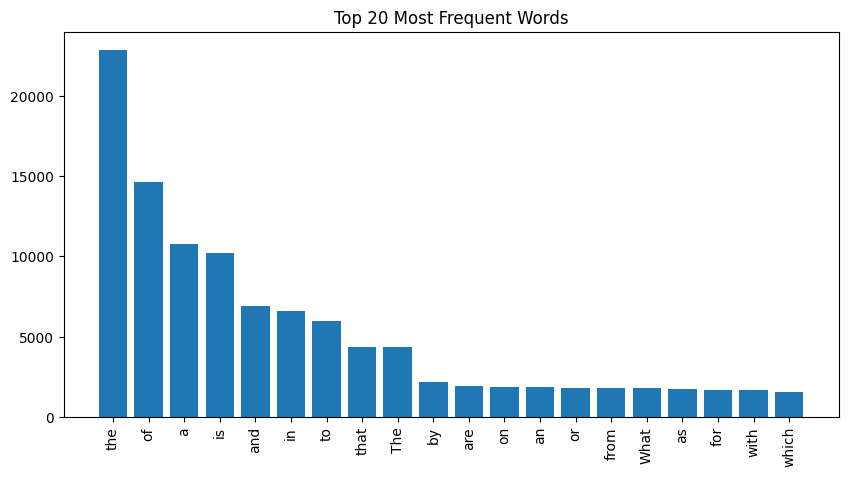

In [32]:
plt.figure(figsize=(10,5))

plt.bar(
    [x[0] for x in top_words],
    [x[1] for x in top_words]
)

plt.xticks(rotation=90)
plt.title("Top 20 Most Frequent Words")

plt.show()

In [33]:
#Text Preprocessing
def clean(text):

    text = str(text).lower()

    text = re.sub(r"[^\w\s]", "", text)

    text = re.sub(r"\s+", " ", text).strip()

    return text

In [34]:
columns = [
    "prompt",
    "A",
    "B",
    "C",
    "D",
    "E"
]

for col in columns:

    train[col] = train[col].apply(clean)

    test[col] = test[col].apply(clean)

In [35]:
sample = pd.read_csv(
    "/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv"
)

print("Before:\n")
print(sample.loc[0,"prompt"])

print("\n")

print("After:\n")
print(train.loc[0,"prompt"])

Before:

Pick the best possible answer: What is Martin Heidegger's view on the relationship between time and human existence? among the listed options.


After:

pick the best possible answer what is martin heideggers view on the relationship between time and human existence among the listed options


In [36]:
sample = train.iloc[0]

print("Prompt:\n")
print(sample["prompt"])

print("\nOption A:\n")
print(sample["A"])

print("\nCombined Input:\n")
print(sample["prompt"] + " [SEP] " + sample["A"])

Prompt:

pick the best possible answer what is martin heideggers view on the relationship between time and human existence among the listed options

Option A:

martin heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end the relationship to the past involves acknowledging it as a historical era and the relationship to the future involves creating a world that will endure beyond ones own time

Combined Input:

pick the best possible answer what is martin heideggers view on the relationship between time and human existence among the listed options [SEP] martin heidegger believes that humans exist within a time continuum that is infinite and does not have a defined beginning or end the relationship to the past involves acknowledging it as a historical era and the relationship to the future involves creating a world that will endure beyond ones own time


In [37]:
#final processed dataset sample
train.head()

,id,prompt,A,B,C,D,E,answer,prompt_length,A_length,B_length,C_length,D_length,E_length,prompt_word_count
0,1,pick the best possible answer what is martin h...,martin heidegger believes that humans exist wi...,martin heidegger believes that humans do not e...,martin heidegger does not believe in the exist...,martin heidegger believes that the relationshi...,martin heidegger believes that time is an illu...,B,142,307,258,222,202,191,22
1,2,what is acceleratorbased lightion fusion,acceleratorbased lightion fusion is a techniqu...,acceleratorbased lightion fusion is a techniqu...,acceleratorbased lightion fusion is a techniqu...,acceleratorbased lightion fusion is a techniqu...,acceleratorbased lightion fusion is a techniqu...,A,43,406,364,365,407,408,5
2,3,determine the correct option what is the term ...,blueshifting,redshifting,reddening,whitening,yellowing,C,182,12,11,9,9,9,27
3,4,select the most accurate option what is martin...,martin heidegger believes that humans exist wi...,martin heidegger believes that humans do not e...,martin heidegger does not believe in the exist...,martin heidegger believes that the relationshi...,martin heidegger believes that time is an illu...,B,129,307,258,222,202,191,19
4,5,identify the correct statement what is the con...,simultaneity is relative meaning that two even...,simultaneity is relative meaning that two even...,simultaneity is absolute meaning that two even...,simultaneity is a concept that applies only to...,simultaneity is a concept that applies only to...,A,110,230,233,233,99,99,15
